In [1]:
import numpy as np
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [3]:
df=pd.read_csv('insurance.csv')
print(df)

      age     sex     bmi  children smoker     region      charges
0      19  female  27.900         0    yes  southwest  16884.92400
1      18    male  33.770         1     no  southeast   1725.55230
2      28    male  33.000         3     no  southeast   4449.46200
3      33    male  22.705         0     no  northwest  21984.47061
4      32    male  28.880         0     no  northwest   3866.85520
...   ...     ...     ...       ...    ...        ...          ...
1333   50    male  30.970         3     no  northwest  10600.54830
1334   18  female  31.920         0     no  northeast   2205.98080
1335   18  female  36.850         0     no  southeast   1629.83350
1336   21  female  25.800         0     no  southwest   2007.94500
1337   61  female  29.070         0    yes  northwest  29141.36030

[1338 rows x 7 columns]


# EDA


In [6]:
df.shape

(1338, 7)

In [7]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [9]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [10]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [4]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')

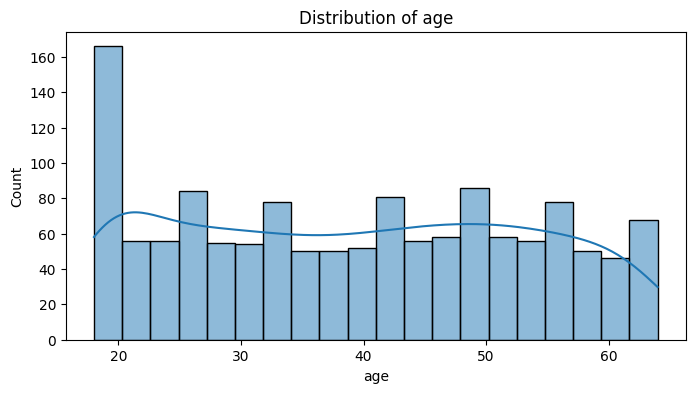

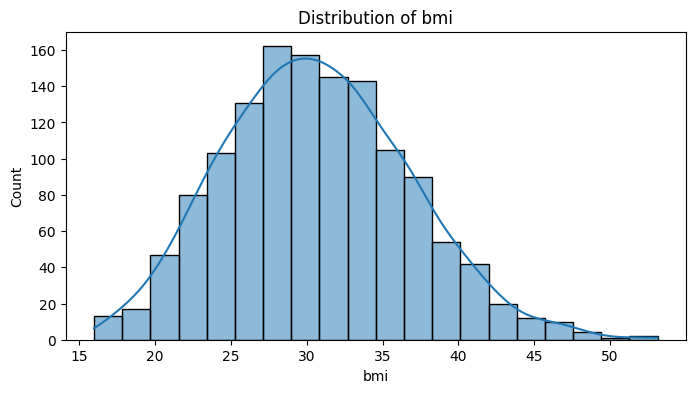

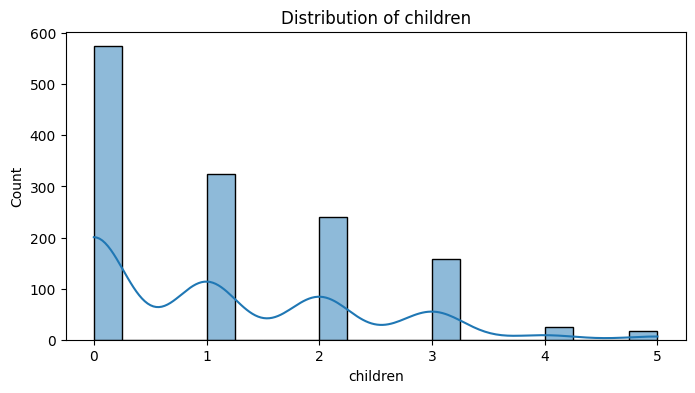

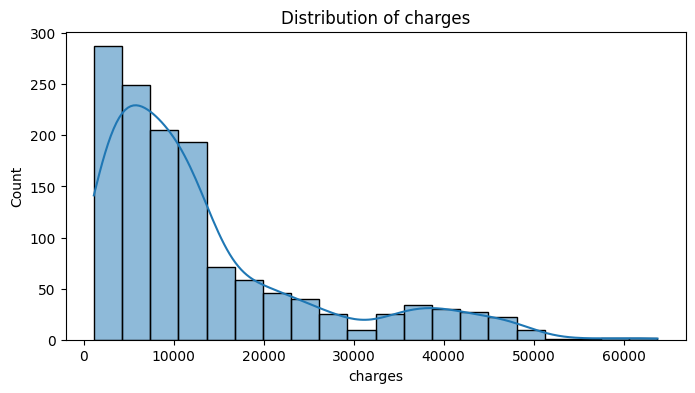

In [7]:
numeric_colnums=['age','bmi','children','charges']

for col in numeric_colnums:
    plt.figure(figsize=(8,4))
    sns.histplot(df[col],kde=True,bins=20)
    plt.title(f'Distribution of {col}')
    plt.show()


<Axes: xlabel='sex', ylabel='count'>

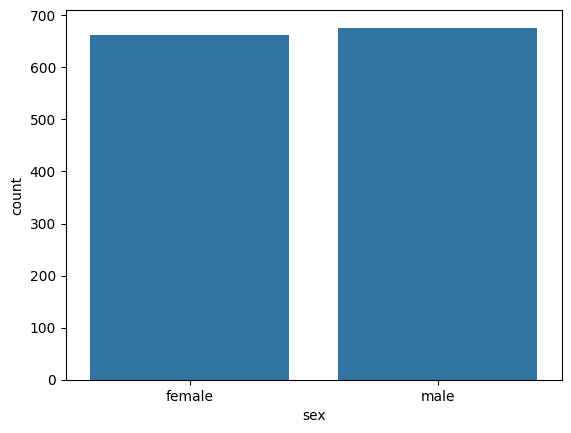

In [9]:
sns.countplot(x='sex',data=df)


<Axes: xlabel='smoker', ylabel='count'>

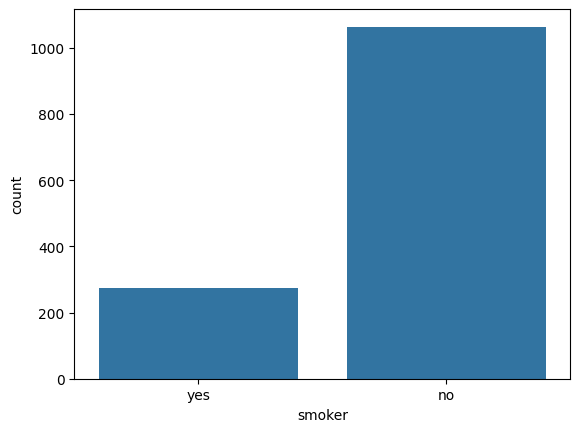

In [10]:
sns.countplot(x='smoker',data=df)

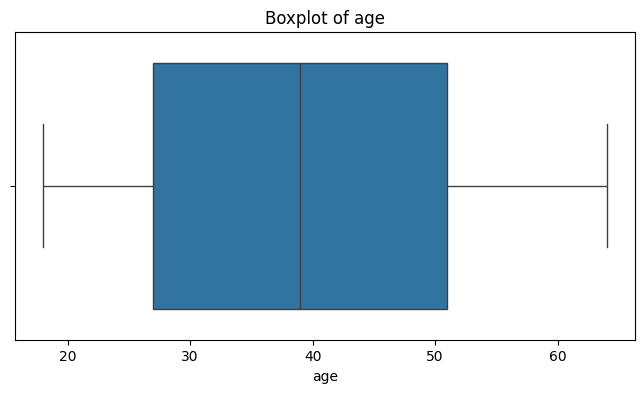

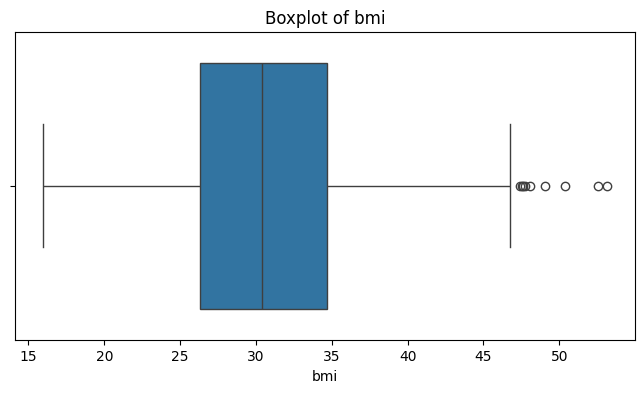

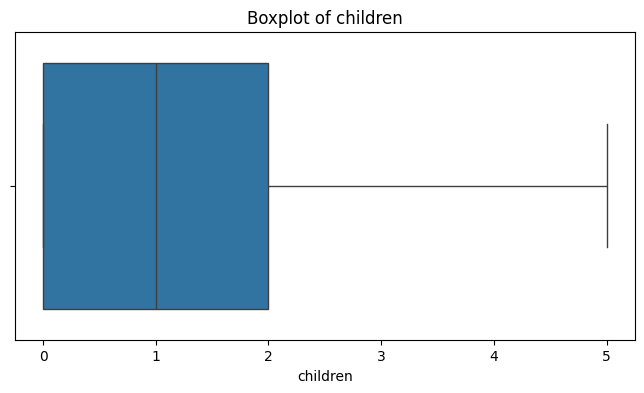

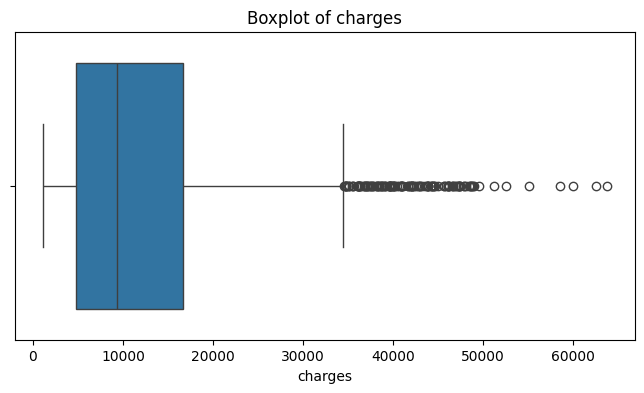

In [11]:
for col in numeric_colnums:
    plt.figure(figsize=(8,4))
    sns.boxplot(x=col,data=df)
    plt.title(f'Boxplot of {col}')
    plt.show()

<Axes: >

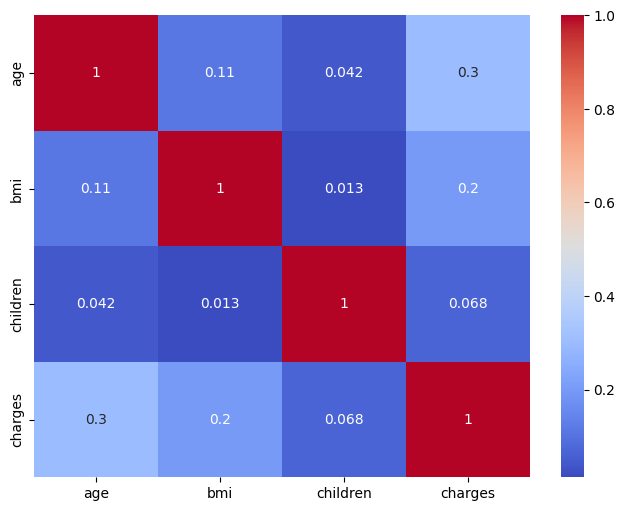

In [15]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap='coolwarm')

# Data cleaning and Processing 

In [16]:
df['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [17]:
df_cleaned = df.copy()

In [18]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [20]:
df_cleaned.shape

(1337, 7)

In [21]:
df_cleaned.drop_duplicates(inplace=True)

In [22]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [23]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [24]:
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

In [25]:
df_cleaned['sex']=df_cleaned['sex'].map({'male':0,'female':1})

In [26]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [27]:
df_cleaned['smoker'].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [28]:
df_cleaned['smoker']=df_cleaned['smoker'].map({'yes':1,'no':0})

In [29]:
df_cleaned['smoker'].value_counts()

smoker
0    1063
1     274
Name: count, dtype: int64

In [30]:
df_cleaned.rename(columns={'sex':'is_female', 'smoker':'is_smoker'},inplace=True)

In [31]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [32]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [33]:
df_cleaned=pd.get_dummies(df_cleaned,columns=['region'],drop_first=True)

In [34]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,False,False,True
1,18,0,33.770,1,0,1725.55230,False,True,False
2,28,0,33.000,3,0,4449.46200,False,True,False
3,33,0,22.705,0,0,21984.47061,True,False,False
4,32,0,28.880,0,0,3866.85520,True,False,False


In [35]:
df_cleaned=df_cleaned.astype(int)

In [37]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,1
1,18,0,33,1,0,1725,0,1,0
2,28,0,33,3,0,4449,0,1,0
3,33,0,22,0,0,21984,1,0,0
4,32,0,28,0,0,3866,1,0,0
...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0
1334,18,1,31,0,0,2205,0,0,0
1335,18,1,36,0,0,1629,0,1,0
1336,21,1,25,0,0,2007,0,0,1


# Feature Engineering and Extraction

<Axes: xlabel='bmi', ylabel='Count'>

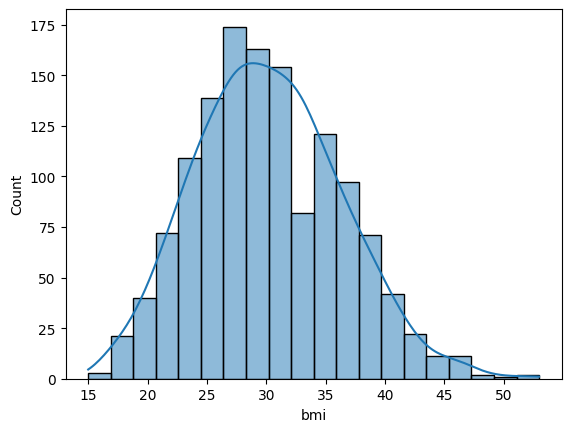

In [39]:
sns.histplot(df_cleaned['bmi'],kde=True,bins=20)


In [40]:
df_cleaned['bmi_category']=pd.cut(
    df_cleaned['bmi'],
    bins=[0, 18.5, 24.9,29.9, float('inf')],
    labels=['Underweight', 'Normal', 'Overweight', 'Obese']
    )

In [41]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27,0,1,16884,0,0,1,Overweight
1,18,0,33,1,0,1725,0,1,0,Obese
2,28,0,33,3,0,4449,0,1,0,Obese
3,33,0,22,0,0,21984,1,0,0,Normal
4,32,0,28,0,0,3866,1,0,0,Overweight
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,Obese
1334,18,1,31,0,0,2205,0,0,0,Obese
1335,18,1,36,0,0,1629,0,1,0,Obese
1336,21,1,25,0,0,2007,0,0,1,Overweight


In [42]:
df_cleaned=pd.get_dummies(df_cleaned,columns=['bmi_category'],drop_first=True)

In [45]:
df_cleaned=df_cleaned.astype(int)

In [46]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,1,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30,3,0,10600,1,0,0,0,0,1
1334,18,1,31,0,0,2205,0,0,0,0,0,1
1335,18,1,36,0,0,1629,0,1,0,0,0,1
1336,21,1,25,0,0,2007,0,0,1,0,1,0


In [47]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northwest', 'region_southeast', 'region_southwest',
       'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='str')

# Scaleing 

In [ ]:
from sklearn.preprocessing import StandardScaler
cols=['age','bmi','children','charges']
scaler=StandardScaler()
df_cleaned[cols]=scaler.fit_transform(df_cleaned[cols])

In [51]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,0.297821,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,-0.954385,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,-0.729370,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,0.719106,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,-0.777528,1,0,0,0,1,0


In [52]:
# 1. Reverse the scaling back to the original values
df_cleaned[cols] = scaler.inverse_transform(df_cleaned[cols])

# 2. Rescale ONLY the feature columns (excluding 'charges')
feature_cols = ['age', 'bmi', 'children']
feature_scaler = StandardScaler()
df_cleaned[feature_cols] = feature_scaler.fit_transform(df_cleaned[feature_cols])

In [ ]:
df_cleaned.head()
#not working

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,0.297821,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,-0.954385,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,-0.729370,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,0.719106,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,-0.777528,1,0,0,0,1,0


In [55]:
# Copy the original charges column back
df_cleaned['charges'] = df['charges']

In [ ]:
df_cleaned.head()


,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884.92400,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725.55230,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449.46200,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984.47061,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866.85520,1,0,0,0,1,0


In [57]:
# Now scale only the input features
feature_cols = ['age', 'bmi', 'children']
feature_scaler = StandardScaler()
df_cleaned[feature_cols] = feature_scaler.fit_transform(df_cleaned[feature_cols])

In [58]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884.92400,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725.55230,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449.46200,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984.47061,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866.85520,1,0,0,0,1,0


# Feature Extraction

In [ ]:
from scipy.stats import pearsonr

selected_features = ['age', 'bmi', 'children', 'is_female', 'is_smoker', 
                    'region_northwest', 'region_southeast', 'region_southwest',
                    'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
                    ]

correlation_results = {
    feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0] 
    for feature in selected_features
}
correlation_df=pd.DataFrame(list(correlation_results.items()), columns=['Feature', 'Pearson Correlation with Charges'])
correlation_df.sort_values(by='Pearson Correlation with Charges', ascending=False, inplace=True)


In [60]:
correlation_df

,Feature,Pearson Correlation with Charges
4,is_smoker,0.787234
0,age,0.298308
10,bmi_category_Obese,0.200347
1,bmi,0.196236
6,region_southeast,0.073578
2,children,0.067389
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058044
8,bmi_category_Normal,-0.104042


In [ ]:
cat_features = ['is_female', 'is_smoker', 
                'region_northwest', 'region_southeast', 'region_southwest',
                'bmi_category_Normal', 'bmi_category_Overweight', 'bmi_category_Obese'
                ]




In [63]:
from scipy.stats import chi2_contingency
import pandas as pd

alpha = 0.05

df_cleaned['charges_bin']=pd.qcut(df_cleaned['charges'], q=4, labels=False)
# Perform chi-square test for each categorical feature
chi_results = {}

for feature in df_cleaned:
    contingency_table = pd.crosstab(df_cleaned[feature], df_cleaned['charges_bin'])
    chi2, p, dof, expected = chi2_contingency(contingency_table)
    decision = "Reject Null Hypothesis" if p < alpha else "Fail to Reject Null Hypothesis(Drop the feature)"
    
    chi_results[feature] = {
        'Chi2 Statistic': chi2,
        'p-value': p,
        'Degrees of Freedom': dof,
        'Decision': decision
    }
    
chi_results_df = pd.DataFrame(chi_results).T
chi_results_df.sort_values(by='p-value', ascending=True, inplace=True)
chi_results_df

,Chi2 Statistic,p-value,Degrees of Freedom,Decision
charges_bin,4011.0,0.0,9,Reject Null Hypothesis
age,1509.13025,0.0,138,Reject Null Hypothesis
is_smoker,848.219178,0.0,3,Reject Null Hypothesis
children,138.659313,0.0,15,Reject Null Hypothesis
region_southeast,15.998167,0.001135,3,Reject Null Hypothesis
is_female,10.258784,0.01649,3,Reject Null Hypothesis
bmi,144.758888,0.017278,111,Reject Null Hypothesis
bmi_category_Obese,8.515711,0.036473,3,Reject Null Hypothesis
region_southwest,5.091893,0.165191,3,Fail to Reject Null Hypothesis(Drop the feature)
bmi_category_Overweight,4.25149,0.235557,3,Fail to Reject Null Hypothesis(Drop the feature)


In [68]:
final_df = df_cleaned[['age', 'bmi', 'children', 'charges','bmi_category_Obese',]]


In [69]:
final_df

,age,bmi,children,charges,bmi_category_Obese
0,-1.440418,-0.517949,-0.909234,16884.92400,0
1,-1.511647,0.462463,-0.079442,1725.55230,1
2,-0.799350,0.462463,1.580143,4449.46200,1
3,-0.443201,-1.334960,-0.909234,21984.47061,0
4,-0.514431,-0.354547,-0.909234,3866.85520,0
...,...,...,...,...,...
1333,0.767704,-0.027743,1.580143,10600.54830,1
1334,-1.511647,0.135659,-0.909234,2205.98080,1
1335,-1.511647,0.952670,-0.909234,1629.83350,1
1336,-1.297958,-0.844753,-0.909234,2007.94500,0
